# Datos Faltantes

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [3]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
235,0.067136,0.050680,-0.014828,0.058608,-0.059359,-0.034508,-0.061809,0.012906,-0.005142,0.048628,124.0
354,-0.023677,0.050680,0.045529,0.021872,0.109883,0.088873,0.000779,0.034309,0.074191,0.061054,272.0
348,0.030811,-0.044642,-0.020218,-0.005670,-0.004321,-0.029497,0.078093,-0.039493,-0.010903,-0.001078,148.0
63,-0.034575,-0.044642,-0.037463,-0.060756,0.020446,0.043466,-0.013948,-0.002592,-0.030748,-0.071494,128.0
98,0.001751,0.050680,-0.005128,-0.012556,-0.015328,-0.013840,0.008142,-0.039493,-0.006081,-0.067351,92.0
364,0.001751,0.050680,-0.006206,-0.019442,-0.009825,0.004949,-0.039719,0.034309,0.014821,0.098333,262.0
185,-0.074533,0.050680,-0.018062,0.008101,-0.019456,-0.024800,-0.065491,0.034309,0.067318,-0.017646,101.0
25,-0.067268,0.050680,-0.012673,-0.040099,-0.015328,0.004636,-0.058127,0.034309,0.019196,-0.034215,202.0
144,0.030811,0.050680,0.046607,-0.015999,0.020446,0.050669,-0.058127,0.071210,0.006207,0.007207,174.0
280,0.009016,0.050680,0.018584,0.039087,0.017694,0.010586,0.019187,-0.002592,0.016307,-0.017646,265.0


In [4]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [5]:
# Ejercicio 1: contar valores faltantes por columna
data.isnull().sum()

,0
age,0
sex,0
bmi,44
bp,44
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [6]:
# Ejercicio 2: imputación simple con la media en 'bmi'
data_simple = data.copy()   # copia de la tabla para no modificar la original

imputer_media = SimpleImputer(strategy='mean')
data_simple[['bmi']] = imputer_media.fit_transform(data_simple[['bmi']])

# Verificar que ya no hay vacíos en 'bmi'
print("Faltantes en bmi:", data_simple['bmi'].isnull().sum())
print("Valor usado para rellenar (media):", imputer_media.statistics_[0])

Faltantes en bmi: 0
Valor usado para rellenar (media): -0.00020486982495318998


### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [7]:
# Ejercicio 3: imputación con KNN en 'bmi' y 'bp'
knn = KNNImputer(n_neighbors=5)   # usará los 5 pacientes más parecidos
data_knn = pd.DataFrame(knn.fit_transform(data), columns=data.columns, index=data.index)

print("Faltantes después de KNN:")
print(data_knn[['bmi', 'bp']].isnull().sum())

# Comparar 'bmi' solo en las filas que estaban vacías
faltantes = data['bmi'].isnull()
comparacion = pd.DataFrame({
    'bmi_media': data_simple.loc[faltantes, 'bmi'],
    'bmi_knn': data_knn.loc[faltantes, 'bmi']
})
comparacion.head(10)

Faltantes después de KNN:
bmi    0
bp     0
dtype: int64


,bmi_media,bmi_knn
9,-0.000205,0.072690
30,-0.000205,0.007806
39,-0.000205,-0.024529
55,-0.000205,-0.000601
70,-0.000205,-0.021511
72,-0.000205,0.010823
73,-0.000205,0.012979
75,-0.000205,-0.033367
76,-0.000205,-0.017631
78,-0.000205,0.006297


**Comparación:** La imputación simple rellenó todos los valores faltantes de 'bmi' con el mismo número (la media, ≈ -0.0002). Esto ignora las características de cada paciente y concentra muchos datos en un solo valor.
KNNImputer, en cambio, asignó un valor distinto a cada fila, basado en los 5 pacientes más parecidos. Por eso sus valores son más realistas y conservan mejor la variación natural de los datos.

### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

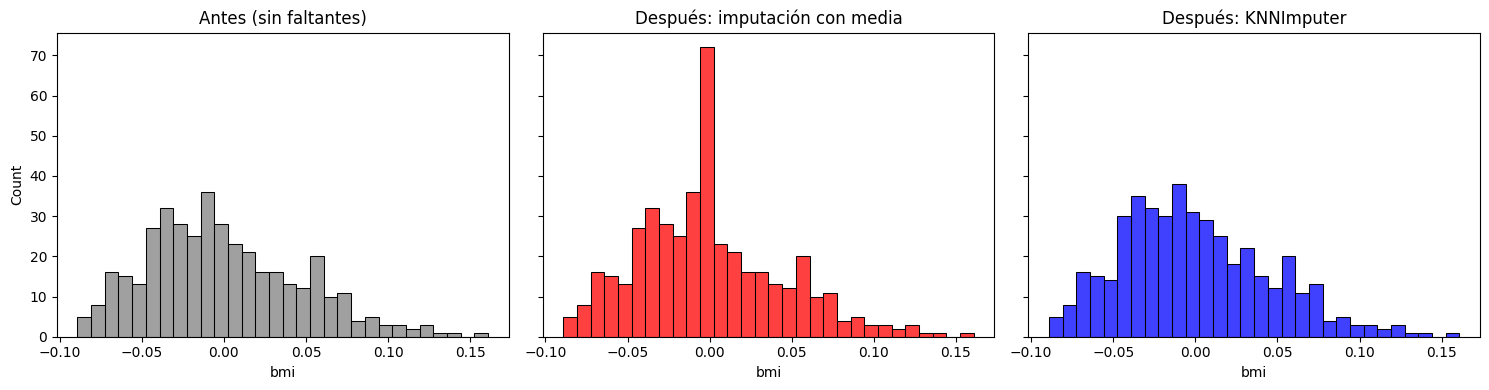

In [8]:
# Ejercicio 4: histograma de 'bmi' antes y después de la imputación
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)   # 1 fila, 3 gráficas

sns.histplot(data['bmi'].dropna(), bins=30, ax=axes[0], color='gray')
axes[0].set_title('Antes (sin faltantes)')

sns.histplot(data_simple['bmi'], bins=30, ax=axes[1], color='red')
axes[1].set_title('Después: imputación con media')

sns.histplot(data_knn['bmi'], bins=30, ax=axes[2], color='blue')
axes[2].set_title('Después: KNNImputer')

plt.tight_layout()
plt.show()

**Conclusión:** En el histograma de la imputación con media aparece un pico artificial cerca de 0, porque los 44 valores faltantes se rellenaron con el mismo número. Esto distorsiona la distribución original de 'bmi'.
Con KNNImputer, el histograma se parece mucho más a los datos originales, ya que cada valor faltante recibió una estimación distinta. Por lo tanto, KNN preserva mejor la forma de los datos.